# 02 — Pack / box EV vs retail

Expected opened value compared to retail price.

Two modes:
1. **Product YAML slots** — quick EV from `ev.slots` in the product config (works for Yugioh tuckboxes).
2. **Card table + slot odds** — detailed Pokémon-style pack model using `data/cards` and `data/odds`.

Replace placeholder market values with your comps before trusting the edge.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if ROOT.name != "notebooks" and (ROOT / "notebooks").is_dir():
    ROOT = ROOT / "notebooks"
sys.path.insert(0, str(ROOT))

from poke_sim import (
    analytical_slot_ev,
    edge,
    edge_pct,
    load_cards,
    load_product,
    load_slot_odds,
    pack_ev_from_slots,
    simulate_pack_openings,
    summarize_openings,
)

## Mode A — product YAML slot EV (Magnificent Monsters box)

In [2]:
PRODUCT = "magnificent_monsters"
RETAIL_OVERRIDE = None  # SEK

product = load_product(PRODUCT)
retail = RETAIL_OVERRIDE if RETAIL_OVERRIDE is not None else product["retail_price_sek"]
slots = product["ev"]["slots"]
box_ev = pack_ev_from_slots(slots)

slot_df = pd.DataFrame(slots)
slot_df["contribution_sek"] = slot_df["count"] * slot_df["expected_value_sek"]
display(slot_df)

print(f"{product['name']}")
print(f"Box EV: {box_ev:.2f} SEK")
print(f"Retail: {retail:.2f} SEK")
print(f"Edge: {edge(box_ev, retail):.2f} SEK ({100*edge_pct(box_ev, retail):.1f}%)")
print(f"Break-even retail: {box_ev:.2f} SEK")

,name,count,expected_value_sek,contribution_sek
0,ultra_pack_slot,15,8,120
1,bonus_secret_slot,3,40,120


Magnificent Monsters
Box EV: 240.00 SEK
Retail: 400.00 SEK
Edge: -160.00 SEK (-40.0%)
Break-even retail: 240.00 SEK


,retail_sek,ev_sek,edge_sek,edge_pct
0,320.0,240.0,-80.0,-0.250000
1,340.0,240.0,-100.0,-0.294118
2,360.0,240.0,-120.0,-0.333333
3,380.0,240.0,-140.0,-0.368421
4,400.0,240.0,-160.0,-0.400000
5,420.0,240.0,-180.0,-0.428571
6,440.0,240.0,-200.0,-0.454545
7,460.0,240.0,-220.0,-0.478261
8,480.0,240.0,-240.0,-0.500000


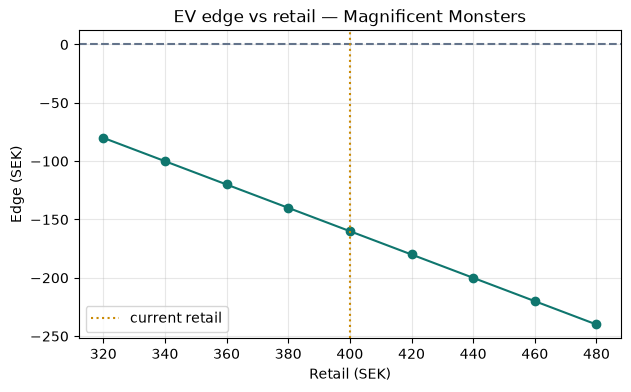

In [3]:
# Retail sensitivity ±20%
grid = np.linspace(retail * 0.8, retail * 1.2, 9)
sens = pd.DataFrame({
    "retail_sek": grid,
    "ev_sek": box_ev,
    "edge_sek": [edge(box_ev, r) for r in grid],
    "edge_pct": [edge_pct(box_ev, r) for r in grid],
})
display(sens)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sens["retail_sek"], sens["edge_sek"], marker="o", color="#0f766e")
ax.axhline(0, color="#64748b", linestyle="--")
ax.axvline(retail, color="#ca8a04", linestyle=":", label="current retail")
ax.set_xlabel("Retail (SEK)")
ax.set_ylabel("Edge (SEK)")
ax.set_title(f"EV edge vs retail — {product['name']}")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

## Mode B — Pokémon pack from cards + odds CSVs

In [4]:
poke = load_product("sample_pokemon_booster")
pack_retail = poke.get("retail_price_per_pack_sek", poke["retail_price_sek"] / poke["packs_per_box"])
box_retail = poke["retail_price_sek"]

cards = load_cards()
cards = cards.loc[cards["set_id"] == "sample_set"].copy()
odds = load_slot_odds()

SLOT_COUNTS = {"common": 4, "uncommon": 3, "rare_plus": 2, "reverse": 1}

slot_ev = analytical_slot_ev(cards, odds, SLOT_COUNTS)
pack_ev = float(slot_ev["ev_total"].sum())
display(slot_ev)

print(f"Analytical pack EV: {pack_ev:.2f} SEK | pack retail: {pack_retail:.2f} SEK")
print(f"Pack edge: {edge(pack_ev, pack_retail):.2f} SEK ({100*edge_pct(pack_ev, pack_retail):.1f}%)")
print(f"Box EV ({poke['packs_per_box']} packs): {pack_ev * poke['packs_per_box']:.2f} SEK | box retail: {box_retail:.2f} SEK")
print(f"Box edge: {edge(pack_ev * poke['packs_per_box'], box_retail):.2f} SEK")

,slot,count,ev_per_slot,ev_total
0,common,4,1.200000,4.800
1,rare_plus,2,36.287500,72.575
2,reverse,1,7.330000,7.330
3,uncommon,3,2.666667,8.000


Analytical pack EV: 92.70 SEK | pack retail: 50.00 SEK
Pack edge: 42.70 SEK (85.4%)
Box EV (36 packs): 3337.38 SEK | box retail: 1800.00 SEK
Box edge: 1537.38 SEK


Monte Carlo pack summary
  mean_ev: 92.61
  median: 62.00
  p5: 28.00
  p95: 186.05
  hit_rate_vs_retail: 0.6486
  edge: 42.61
  edge_pct: 0.8522
  retail: 50.00
  n: 20000.00


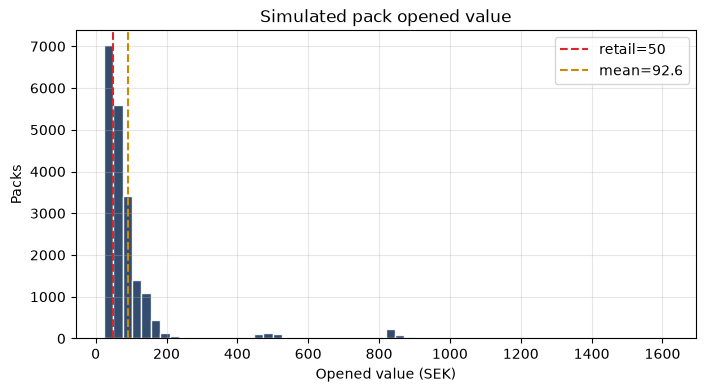

In [5]:
N = 20_000
sims = simulate_pack_openings(cards, odds, SLOT_COUNTS, n=N, rng=np.random.default_rng(42))
summary = summarize_openings(sims["opened_value_sek"], pack_retail)
print("Monte Carlo pack summary")
for k, v in summary.items():
    print(f"  {k}: {v:.4f}" if abs(v) < 10 else f"  {k}: {v:.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(sims["opened_value_sek"], bins=60, color="#1e3a5f", edgecolor="white", alpha=0.9)
ax.axvline(pack_retail, color="#dc2626", linestyle="--", label=f"retail={pack_retail:.0f}")
ax.axvline(summary["mean_ev"], color="#ca8a04", linestyle="--", label=f"mean={summary['mean_ev']:.1f}")
ax.set_xlabel("Opened value (SEK)")
ax.set_ylabel("Packs")
ax.set_title("Simulated pack opened value")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

### Notes

- Values are **raw singles** comps you provide — no fees/shipping haircut in v1.
- Pull weights in `data/odds/sample_slot_odds.csv` are editable placeholders.
- For Yugioh GMR chase probability (not EV), use `01_boxes_to_chase.ipynb`.